In [3]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

# Set consistent plotting style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

print("Environment and libraries initialized successfully.")

Environment and libraries initialized successfully.


## Load Datasets

In [4]:
# Update paths as needed for your local environment
TRAIN_PATH = r"D:\IIIT Bangalore\Sem-1\Machine Learning\Machine Learning Projects\Industrial Machine Fault Prediction\student_dataset.csv"
TEST_PATH  = r"D:\IIIT Bangalore\Sem-1\Machine Learning\Machine Learning Projects\Industrial Machine Fault Prediction\test.csv"

train = pd.read_csv(TRAIN_PATH)
print(f"Train dataset loaded: {train.shape[0]:,} rows, {train.shape[1]} columns")

test = pd.read_csv(TEST_PATH)
print(f"Test dataset loaded:  {test.shape[0]:,} rows, {test.shape[1]} columns")


Train dataset loaded: 16,000 rows, 13 columns
Test dataset loaded:  4,000 rows, 12 columns


## Exploratory Data Analysis (EDA)

### 1. Dataset Structure, Summary Statistics & Missing Values
 In `student_dataset.csv` (16,000 rows × 13 columns):
- **Identifiers & Target**: `unit_id` (unique identifier) and `condition` (target classes `0`, `1`, `2`) have **0 missing values**.
- **Missing Sensor Readings**: All 10 numerical sensor features and `unit_type` have a small percentage of missing values ranging from **0.14% (`unit_type`, 22 rows)** to **0.46% (`vibration_index`, 74 rows)**, affecting **240 rows (1.50% of the dataset)** in total.


DATASET INFO & DATA TYPES
<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   unit_id          16000 non-null  str    
 1   unit_type        15978 non-null  str    
 2   ambient_temp     15953 non-null  float64
 3   process_temp     15955 non-null  float64
 4   coolant_flow     15939 non-null  float64
 5   shaft_speed      15968 non-null  float64
 6   drive_torque     15964 non-null  float64
 7   power_load       15975 non-null  float64
 8   component_wear   15944 non-null  float64
 9   thermal_stress   15950 non-null  float64
 10  mechanical_load  15955 non-null  float64
 11  vibration_index  15926 non-null  float64
 12  condition        16000 non-null  int64  
dtypes: float64(10), int64(1), str(2)
memory usage: 1.6 MB

SUMMARY STATISTICS (NUMERICAL FEATURES)


,count,mean,std,min,25%,50%,75%,max
ambient_temp,15953.0,25.981,4.926,12.000,22.300,24.900,29.900,41.200
process_temp,15955.0,60.986,11.099,33.600,52.900,59.800,67.600,116.900
coolant_flow,15939.0,17.877,6.113,7.820,12.380,17.620,22.130,37.140
shaft_speed,15968.0,1519.400,262.653,824.000,1324.000,1496.000,1693.000,2574.000
drive_torque,15964.0,55.029,11.449,25.100,46.800,54.100,62.400,95.000
power_load,15975.0,8.962,3.137,2.749,6.619,8.444,10.817,23.956
component_wear,15944.0,108.326,67.347,3.000,58.000,94.000,144.000,340.000
thermal_stress,15950.0,27.674,10.805,7.360,19.660,25.745,33.760,84.670
mechanical_load,15955.0,72.483,24.233,25.490,53.480,68.090,88.885,180.420
vibration_index,15926.0,1.691,0.494,0.612,1.337,1.617,1.965,5.534



Total rows with at least one missing value: 240 (1.50%)


,Missing Count,Missing (%),Dtype
vibration_index,74,0.46,float64
coolant_flow,61,0.38,float64
component_wear,56,0.35,float64
thermal_stress,50,0.31,float64
ambient_temp,47,0.29,float64
mechanical_load,45,0.28,float64
process_temp,45,0.28,float64
drive_torque,36,0.22,float64
shaft_speed,32,0.20,float64
power_load,25,0.16,float64


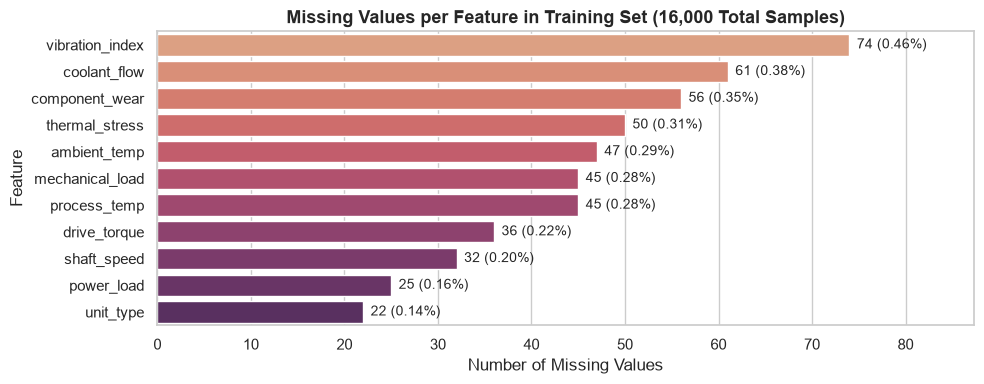

In [5]:
print("="*60)
print("DATASET INFO & DATA TYPES")
print("="*60)
train.info()

print("\n" + "="*60)
print("SUMMARY STATISTICS (NUMERICAL FEATURES)")
print("="*60)
num_cols = [c for c in train.select_dtypes(include=[np.number]).columns if c != "condition"]
display(train[num_cols].describe().T.round(3))

# Missing values summary table
missing_cnt = train.isnull().sum()
missing_pct = (missing_cnt / len(train) * 100).round(2)
missing_df = pd.DataFrame({
    "Missing Count": missing_cnt,
    "Missing (%)": missing_pct,
    "Dtype": train.dtypes
}).query("`Missing Count` > 0").sort_values("Missing Count", ascending=False)

print(f"\nTotal rows with at least one missing value: {train.isnull().any(axis=1).sum()} ({train.isnull().any(axis=1).mean()*100:.2f}%)")
display(missing_df)

# Visualize missing values
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(
    x=missing_df["Missing Count"],
    y=missing_df.index,
    hue=missing_df.index,
    palette="flare",
    legend=False,
    ax=ax
)
for i, (cnt, pct) in enumerate(zip(missing_df["Missing Count"], missing_df["Missing (%)"])):
    ax.text(cnt + 0.8, i, f"{cnt} ({pct:.2f}%)", va="center", fontsize=10)
ax.set_title("Missing Values per Feature in Training Set (16,000 Total Samples)")
ax.set_xlabel("Number of Missing Values")
ax.set_ylabel("Feature")
ax.set_xlim(0, missing_df["Missing Count"].max() * 1.18)
plt.tight_layout()
plt.show()

### 2. Target (`condition`) & Categorical (`unit_type`) Distributions
- **Target Balance**: Class `0` (Normal/Healthy) accounts for **50.0% (8,000 units)**, Class `1` accounts for **25.0% (4,000 units)**, and Class `2` accounts for **25.0% (4,000 units)**. Because of the 2:1:1 class ratio, we use **5-Fold Stratified Cross-Validation** and evaluate both **Accuracy** and **Macro F1 / Log-Loss**.
- **Unit Type Breakdown**: Small (`S`: 45.14%), Medium (`M`: 34.61%), and Heavy (`H`: 20.11%) machines exhibit distinct failure modes: Heavy (`H`) units have the highest rate of **Condition 1 (42.45%)**, whereas Small (`S`) units have the highest rate of **Condition 2 (29.41%)**.


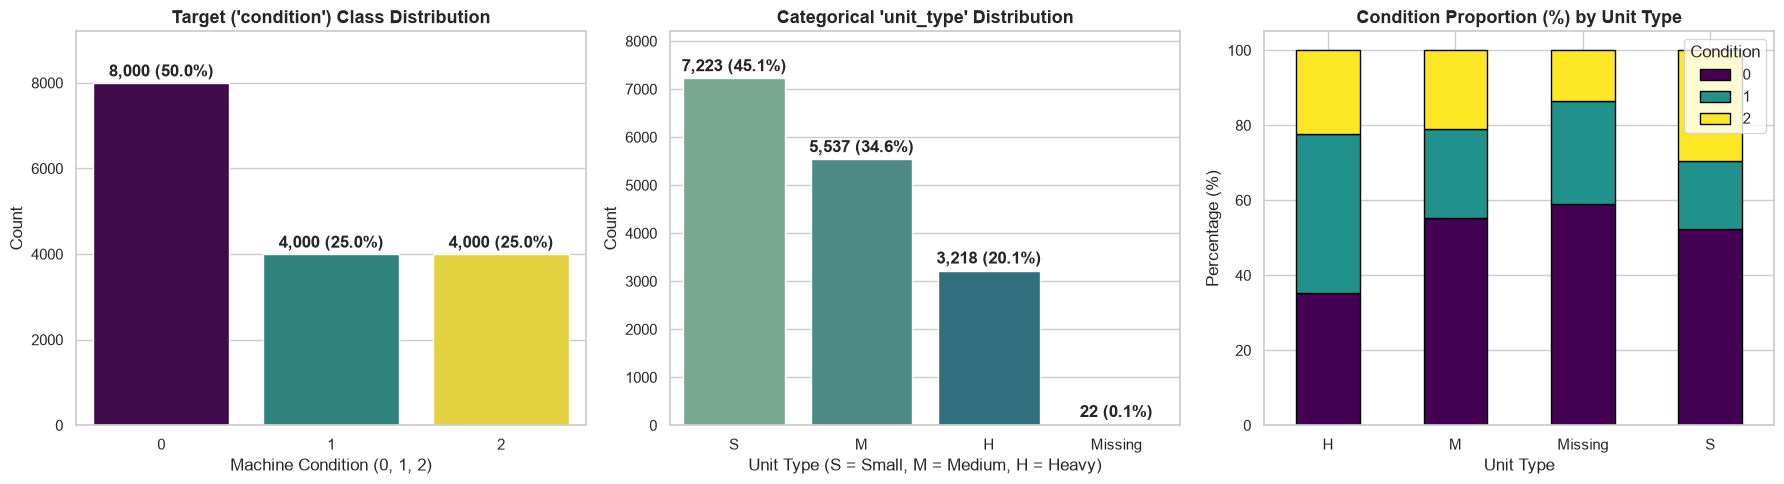

Cross-Tabulation of Unit Type vs. Condition (Row Percentages %):


condition,0,1,2
unit_type,,,
H,35.30,42.45,22.25
M,55.34,23.77,20.90
Missing,59.09,27.27,13.64
S,52.43,18.16,29.41


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Target Condition Distribution
cond_counts = train["condition"].value_counts().sort_index()
sns.barplot(x=cond_counts.index, y=cond_counts.values, hue=cond_counts.index, palette="viridis", legend=False, ax=axes[0])
for i, v in enumerate(cond_counts.values):
    axes[0].text(i, v + 150, f"{v:,} ({v/len(train)*100:.1f}%)", ha="center", fontweight="bold")
axes[0].set_title("Target ('condition') Class Distribution")
axes[0].set_xlabel("Machine Condition (0, 1, 2)")
axes[0].set_ylabel("Count")
axes[0].set_ylim(0, 9200)

# 2. Unit Type Distribution
ut_counts = train["unit_type"].fillna("Missing").value_counts()
sns.barplot(x=ut_counts.index, y=ut_counts.values, hue=ut_counts.index, palette="crest", legend=False, ax=axes[1])
for i, v in enumerate(ut_counts.values):
    axes[1].text(i, v + 150, f"{v:,} ({v/len(train)*100:.1f}%)", ha="center", fontweight="bold")
axes[1].set_title("Categorical 'unit_type' Distribution")
axes[1].set_xlabel("Unit Type (S = Small, M = Medium, H = Heavy)")
axes[1].set_ylabel("Count")
axes[1].set_ylim(0, 8200)

# 3. Cross-Tabulation: Unit Type vs Condition (%)
ct_pct = pd.crosstab(train["unit_type"].fillna("Missing"), train["condition"], normalize="index") * 100
ct_pct.plot(kind="bar", stacked=True, colormap="viridis", ax=axes[2], edgecolor="black")
axes[2].set_title("Condition Proportion (%) by Unit Type")
axes[2].set_xlabel("Unit Type")
axes[2].set_ylabel("Percentage (%)")
axes[2].legend(title="Condition", loc="upper right")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Cross-Tabulation of Unit Type vs. Condition (Row Percentages %):")
display(ct_pct.round(2))

### 3. Sensor Feature Distributions Across Machine Conditions
Comparing sensor distributions across the three machine conditions reveals two distinct physical failure signatures:
- **Condition 1 (Thermal / High-Power Regime)**: Characterized by elevated `process_temp` (mean **72.44°C** vs. 54.67°C in Condition 0), high `thermal_stress` (mean **37.85** vs. 21.32), high `shaft_speed` (**1,697.9 RPM**), high `drive_torque` (**63.93 Nm**), and high `power_load` (**11.60 kW**).
- **Condition 2 (Mechanical Wear & Vibration Regime)**: Characterized by severe `component_wear` (mean **164.99** vs. 87.42 in Condition 0), high `mechanical_load` (**88.00**), and spiked `vibration_index` (**2.10** vs. 1.51).


Mean Sensor Values by Machine Condition:


condition,0,1,2
ambient_temp,25.225,28.105,25.372
process_temp,54.672,72.436,62.172
coolant_flow,17.489,19.150,17.381
shaft_speed,1399.345,1697.914,1580.933
drive_torque,49.126,63.928,57.936
power_load,7.301,11.600,9.649
component_wear,87.415,93.516,164.985
thermal_stress,21.317,37.853,30.230
mechanical_load,64.762,72.405,87.998
vibration_index,1.510,1.644,2.099


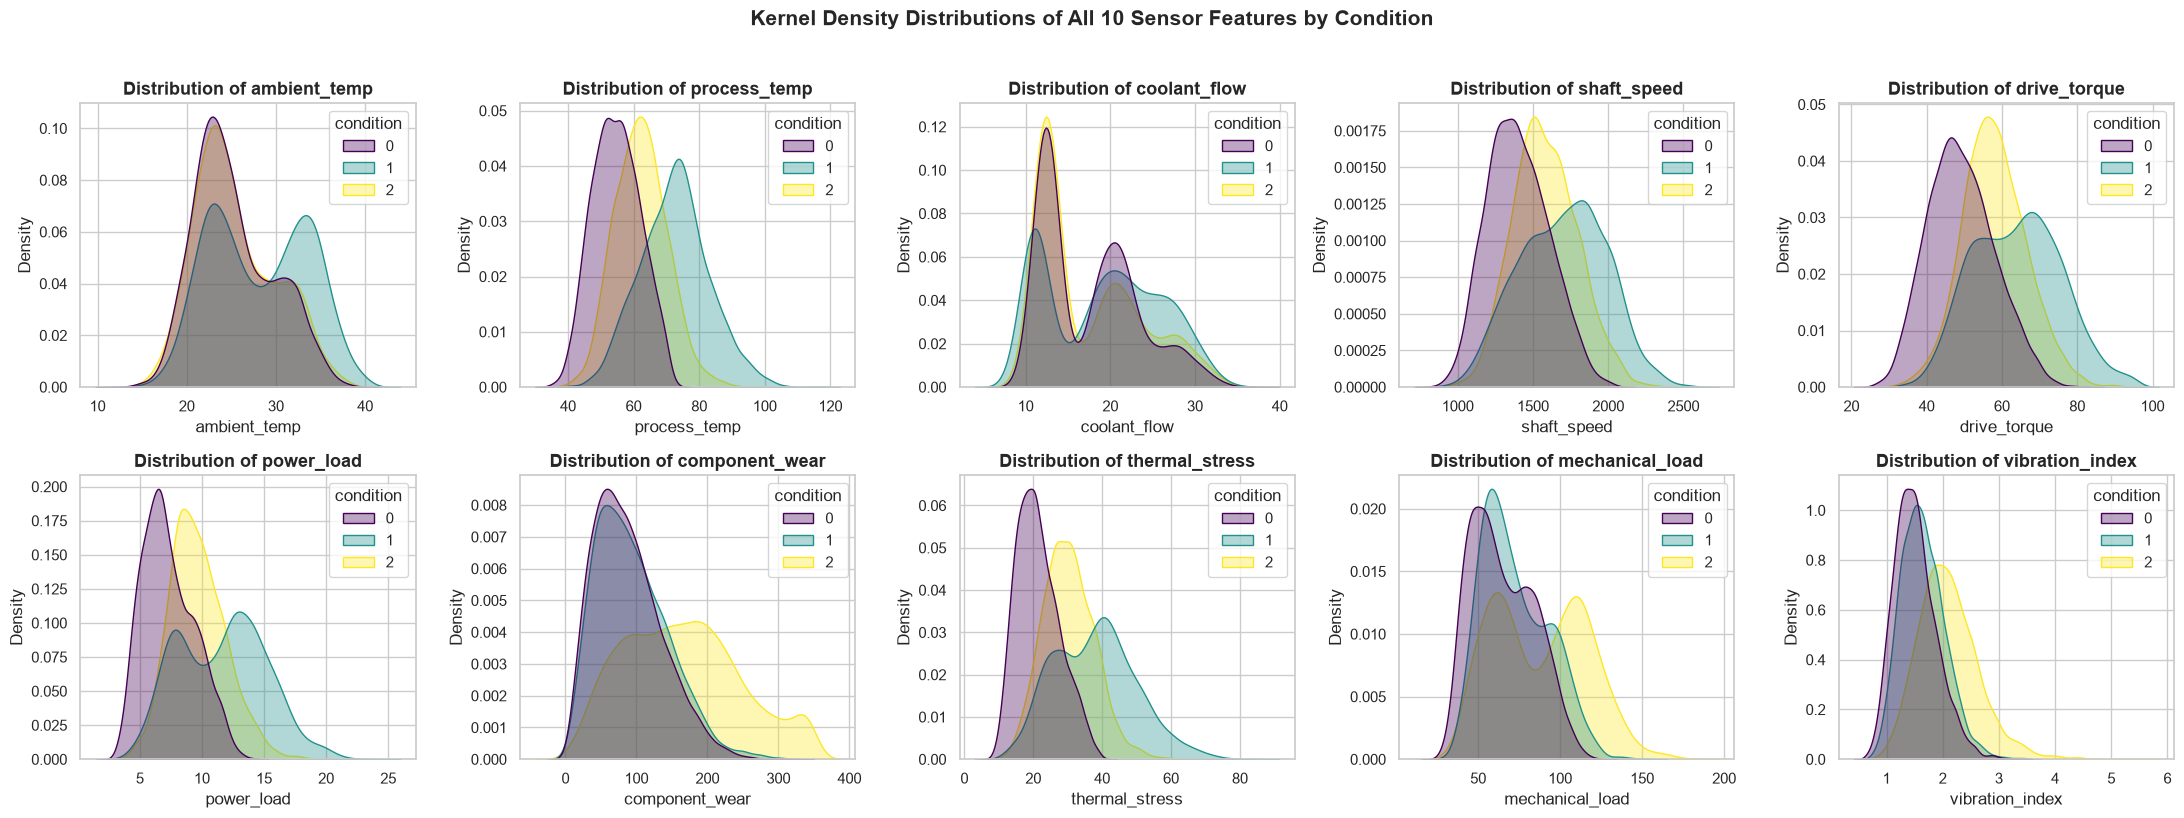

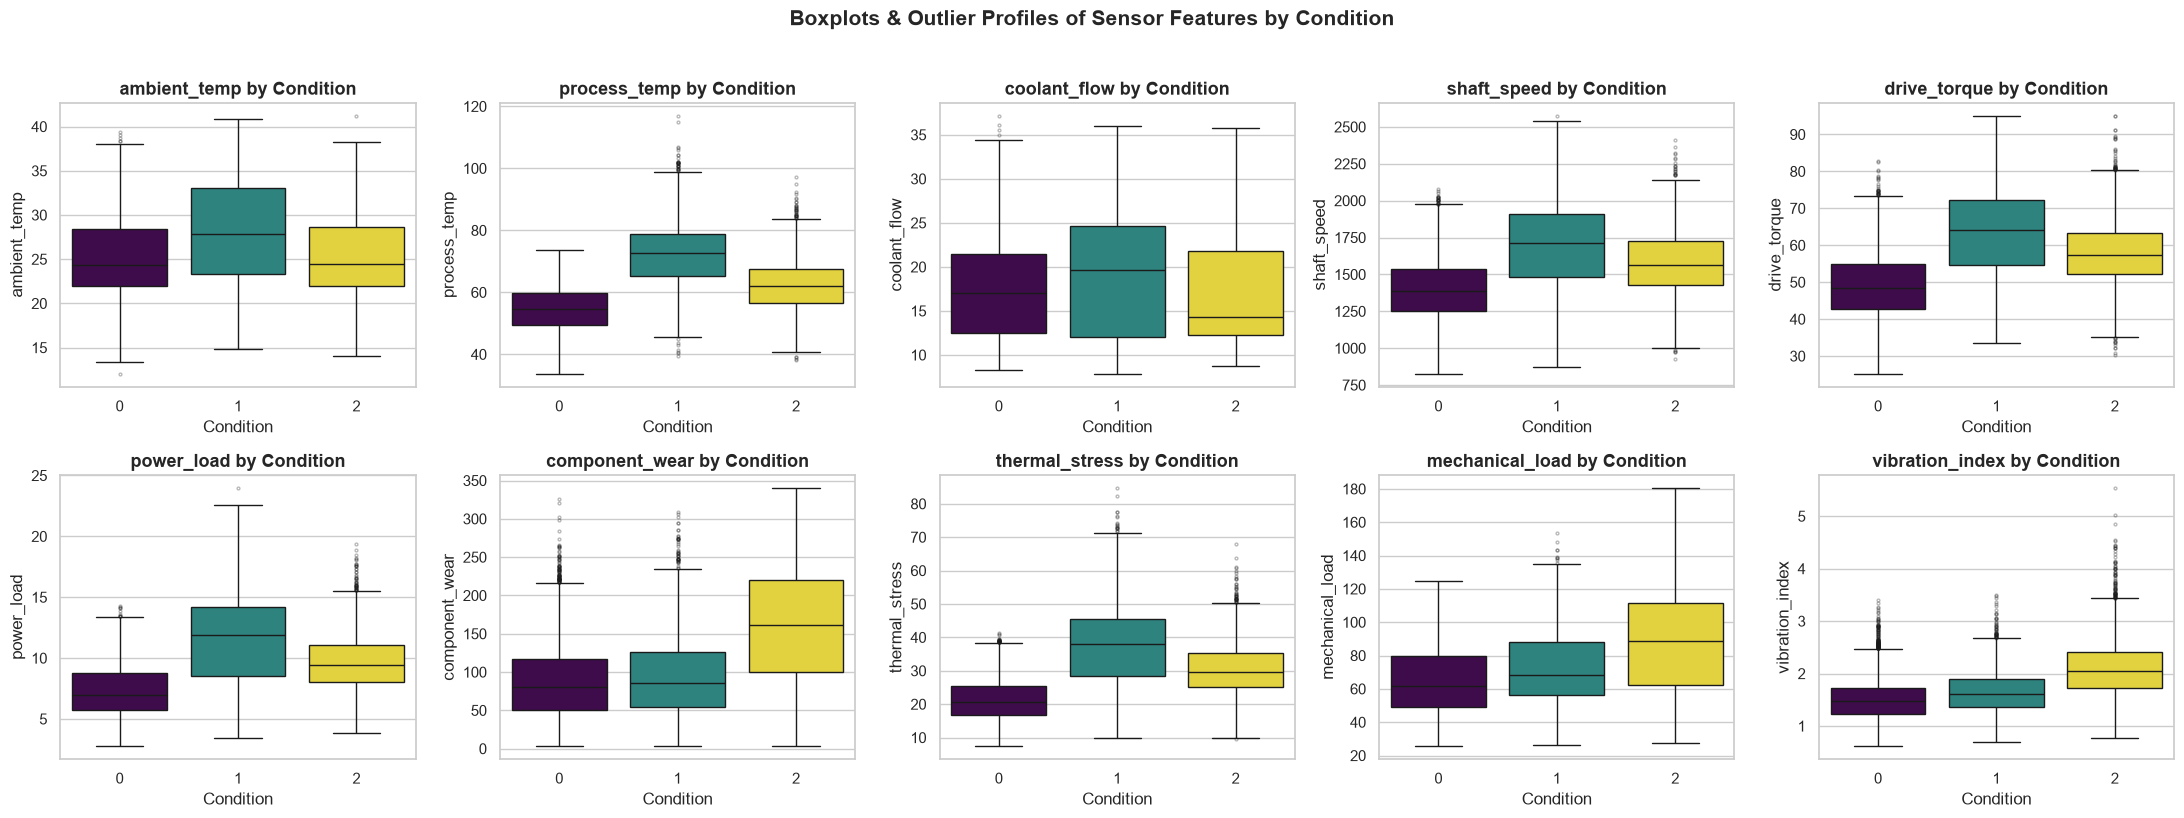

In [7]:
print("Mean Sensor Values by Machine Condition:")
display(train.groupby("condition")[num_cols].mean().round(3).T)

# Plot KDE distributions for all 10 numerical features by Condition
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.kdeplot(
        data=train,
        x=col,
        hue="condition",
        palette="viridis",
        fill=True,
        common_norm=False,
        alpha=0.35,
        ax=axes[idx]
    )
    axes[idx].set_title(f"Distribution of {col}")
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel("Density")

plt.suptitle("Kernel Density Distributions of All 10 Sensor Features by Condition", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# Boxplots to inspect medians, IQRs, and outliers across conditions
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.boxplot(
        data=train,
        x="condition",
        y=col,
        hue="condition",
        palette="viridis",
        legend=False,
        ax=axes[idx],
        flierprops={"marker": "o", "markersize": 2, "alpha": 0.3}
    )
    axes[idx].set_title(f"{col} by Condition")
    axes[idx].set_xlabel("Condition")
    axes[idx].set_ylabel(col)

plt.suptitle("Boxplots & Outlier Profiles of Sensor Features by Condition", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 4. Correlation Matrix & Multi-Sensor Physical Interactions
Inspecting pairwise correlations and 2D physical interaction spaces (`process_temp` vs. `thermal_stress`, `component_wear` vs. `vibration_index`, and `shaft_speed` vs. `drive_torque`) shows why physics-informed interaction features are critical for separating the three classes.


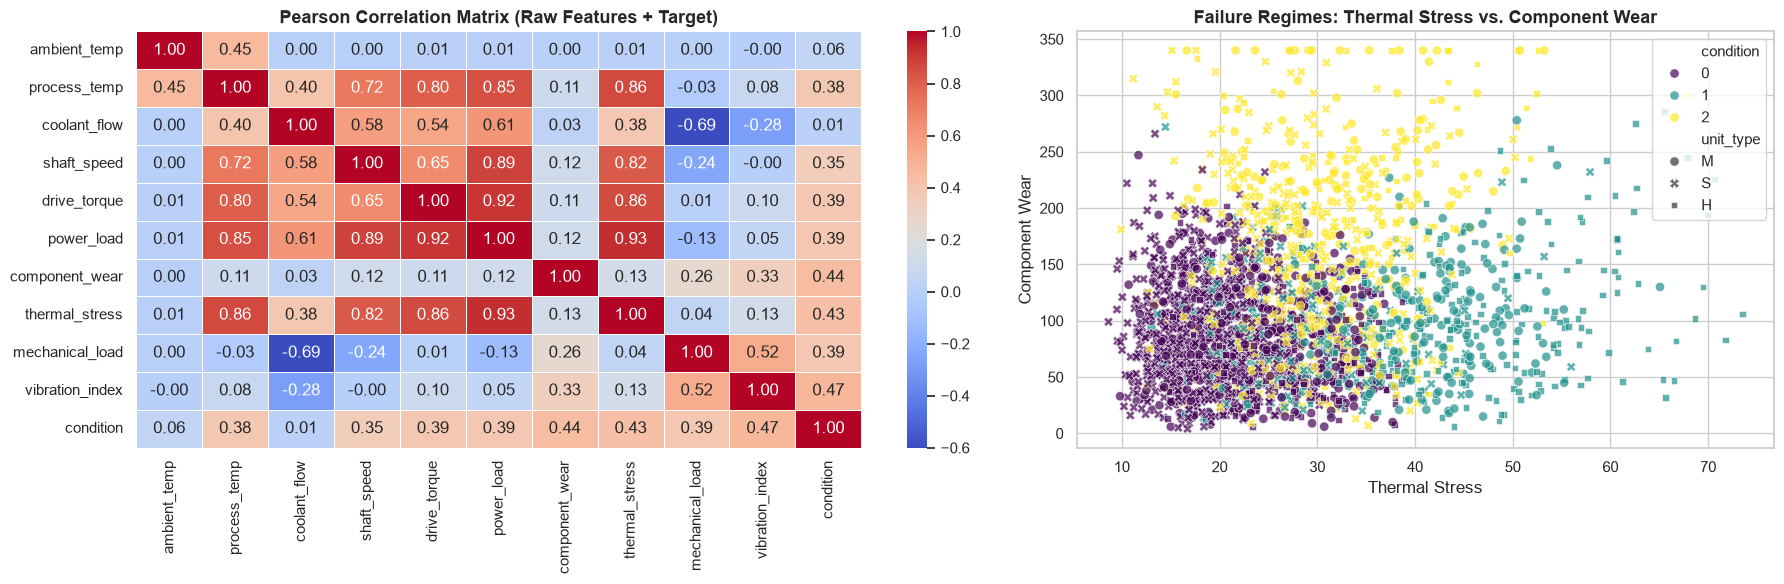

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1.3, 1]})

# 1. Correlation Heatmap
corr_matrix = train[num_cols + ["condition"]].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-0.6,
    vmax=1.0,
    linewidths=0.5,
    ax=axes[0]
)
axes[0].set_title("Pearson Correlation Matrix (Raw Features + Target)")

# 2. Scatter plot of Thermal Stress vs Component Wear colored by Condition
sample_df = train.dropna().sample(n=2500, random_state=42)
sns.scatterplot(
    data=sample_df,
    x="thermal_stress",
    y="component_wear",
    hue="condition",
    style="unit_type",
    palette="viridis",
    alpha=0.7,
    s=45,
    ax=axes[1]
)
axes[1].set_title("Failure Regimes: Thermal Stress vs. Component Wear")
axes[1].set_xlabel("Thermal Stress")
axes[1].set_ylabel("Component Wear")

plt.tight_layout()
plt.show()

## Feature Engineering & Preprocessing
We now apply the `build_features(df)` function from the pipeline, which engineers **30 domain-specific features** (resulting in **40 total features**), and compute median-imputed datasets (`X_imp`, `X_test_imp`) for models that do not natively handle `NaN` values (`ExtraTreesClassifier`).


Total features after unit-type normalization: 60


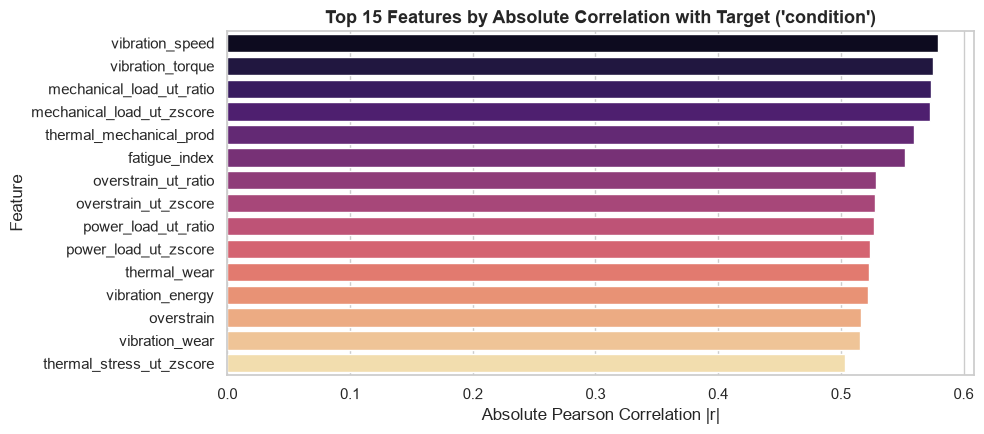

In [9]:
def build_features(df):
    f = df.copy()

    # 1. Physical Constant & Rotational Power Reconstruction
    omega_const = 2 * np.pi / 60000
    calc_power = f["shaft_speed"] * f["drive_torque"] * omega_const

    # Reconstruct missing unit_type from coolant_flow regime if missing
    # S: 8-16 L/min | M: 16-24 L/min | H: 24-37 L/min
    if "unit_type" in f.columns:
        inferred_ut = np.where(f["coolant_flow"] < 15.5, "S",
                      np.where(f["coolant_flow"] > 23.5, "H", "M"))
        f["unit_type"] = f["unit_type"].fillna(pd.Series(inferred_ut, index=f.index))
        type_map = {"S": 0, "M": 1, "H": 2}
        f["unit_type_num"] = f["unit_type"].map(type_map).fillna(1).astype(int)
    else:
        f["unit_type_num"] = 1

    # 2. Base Physics & Thermal Relationships
    temp_diff = f["process_temp"] - f["ambient_temp"]
    f["temp_diff"] = temp_diff
    f["temp_ratio"] = f["process_temp"] / (f["ambient_temp"].replace(0, np.nan))

    f["calc_power"] = calc_power
    f["power_diff"] = f["power_load"] - calc_power
    f["power_ratio"] = f["power_load"] / (calc_power.replace(0, np.nan))

    # Heat dissipation & cooling efficiency
    f["heat_dissipation"] = temp_diff / (f["coolant_flow"].replace(0, np.nan))
    f["cooling_rate"] = f["coolant_flow"] * temp_diff
    f["coolant_per_temp"] = f["coolant_flow"] / (f["process_temp"].replace(0, np.nan))
    f["thermal_load_ratio"] = f["thermal_stress"] / (temp_diff.replace(0, np.nan))

    # Mechanical wear & overstrain indicators
    f["overstrain"] = f["drive_torque"] * f["component_wear"]
    f["speed_torque"] = f["shaft_speed"] * f["drive_torque"]
    f["wear_speed"] = f["component_wear"] * f["shaft_speed"]
    f["wear_per_speed"] = f["component_wear"] / (f["shaft_speed"].replace(0, np.nan))
    f["wear_per_torque"] = f["component_wear"] / (f["drive_torque"].replace(0, np.nan))

    # Vibration dynamics
    f["vibration_energy"] = (f["vibration_index"] ** 2) * f["shaft_speed"]
    f["vibration_torque"] = f["vibration_index"] * f["drive_torque"]
    f["vibration_load"] = f["vibration_index"] * f["mechanical_load"]
    f["vibration_wear"] = f["vibration_index"] * f["component_wear"]
    f["vibration_speed"] = f["vibration_index"] * f["shaft_speed"]

    # Stress interactions
    f["thermal_mechanical_ratio"] = f["thermal_stress"] / (f["mechanical_load"].replace(0, np.nan))
    f["thermal_mechanical_prod"] = f["thermal_stress"] * f["mechanical_load"]
    f["load_wear"] = f["mechanical_load"] * f["component_wear"]
    f["thermal_wear"] = f["thermal_stress"] * f["component_wear"]
    f["torque_stress"] = f["drive_torque"] * f["thermal_stress"]
    f["power_stress"] = f["power_load"] * f["thermal_stress"]
    f["fatigue_index"] = f["mechanical_load"] * f["shaft_speed"]

    # --------------------------------------------------------------------------
    # 3. UNIT_TYPE NORMALIZED FEATURES (Z-Scores & Relative Ratios)
    # --------------------------------------------------------------------------
    # Normalizes sensor readings against each unit_type's specific distribution
    group_cols = [
        "thermal_stress", "mechanical_load", "process_temp", "temp_diff",
        "coolant_flow", "power_load", "drive_torque", "shaft_speed",
        "vibration_index", "component_wear", "overstrain"
    ]
    for col in group_cols:
        grp_mean = f.groupby("unit_type_num")[col].transform("mean")
        grp_std = f.groupby("unit_type_num")[col].transform("std").replace(0, 1.0)
        
        # Standard deviation distance from this unit type's expected baseline
        f[f"{col}_ut_zscore"] = (f[col] - grp_mean) / grp_std
        # Multiplicative ratio relative to this unit type's average operating level
        f[f"{col}_ut_ratio"] = f[col] / grp_mean.replace(0, np.nan)

    # Composite failure severity score combining normalized thermal, mechanical & wear anomalies
    f["composite_risk_index"] = (
        (f["thermal_stress_ut_zscore"] ** 2) +
        (f["mechanical_load_ut_zscore"] ** 2) +
        (f["component_wear_ut_zscore"] ** 2)
    )

    drop_cols = ["unit_type"] if "unit_type" in f.columns else []
    return f.drop(columns=drop_cols)

# Build feature matrices
y = train["condition"].values
X = build_features(train.drop(columns=["unit_id", "condition"]))
X_test = build_features(test.drop(columns=["unit_id"])) if test is not None else None

# Median imputation for models that require complete data
features = X.columns.tolist()
median_vals = X.median()
X_imp = X.fillna(median_vals)
X_test_imp = X_test.fillna(median_vals) if X_test is not None else None

print(f"Total features after unit-type normalization: {len(features)}")

# Plot top 15 features correlated with condition
eng_corr = X.assign(condition=y).corr()["condition"].abs().drop("condition").sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=eng_corr.values, y=eng_corr.index, hue=eng_corr.index, palette="magma", legend=False)
plt.title("Top 15 Features by Absolute Correlation with Target ('condition')")
plt.xlabel("Absolute Pearson Correlation |r|")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## Cross-Validation Setup & Unified Metrics Evaluation Helper
We use a **5-Fold Stratified K-Fold** split (`random_state=42`) so all baseline models, fine-tuned models, and the final ensemble are evaluated on the exact same folds. The helper function `evaluate_model_oof` computes:
- **Accuracy**
- **Multi-Class Log-Loss**
- **Macro & Weighted Precision, Recall, and F1-Score**
- **Multi-Class ROC-AUC (One-vs-Rest)**
- **Per-Class Classification Report & Confusion Matrix**

In [10]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)

# Registry to store metrics across all stages (Baseline, Fine-Tuned, Ensemble)
metrics_registry = []

def evaluate_model_oof(y_true, oof_probs, model_name, stage="Baseline", plot_cm=True):
    preds = np.argmax(oof_probs, axis=1)
    acc = accuracy_score(y_true, preds)
    ll = log_loss(y_true, oof_probs)
    prec_macro = precision_score(y_true, preds, average="macro")
    rec_macro = recall_score(y_true, preds, average="macro")
    f1_macro = f1_score(y_true, preds, average="macro")
    f1_weighted = f1_score(y_true, preds, average="weighted")
    roc_auc = roc_auc_score(y_true, oof_probs, multi_class="ovr", average="macro")

    metrics_dict = {
        "Model": model_name,
        "Stage": stage,
        "Accuracy (%)": round(acc * 100, 3),
        "Log-Loss": round(ll, 4),
        "Macro Precision (%)": round(prec_macro * 100, 3),
        "Macro Recall (%)": round(rec_macro * 100, 3),
        "Macro F1 (%)": round(f1_macro * 100, 3),
        "Weighted F1 (%)": round(f1_weighted * 100, 3),
        "ROC-AUC (OvR)": round(roc_auc, 4)
    }
    # Update or append in registry
    metrics_registry[:] = [m for m in metrics_registry if not (m["Model"] == model_name and m["Stage"] == stage)]
    metrics_registry.append(metrics_dict)

    print("=" * 65)
    print(f"{model_name.upper()} ({stage.upper()}) - 5-FOLD OOF METRICS")
    print("=" * 65)
    print(f"  OOF Accuracy       : {acc*100:.3f}%")
    print(f"  OOF Log-Loss       : {ll:.4f}")
    print(f"  Macro Precision    : {prec_macro*100:.3f}%")
    print(f"  Macro Recall       : {rec_macro*100:.3f}%")
    print(f"  Macro F1-Score     : {f1_macro*100:.3f}%")
    print(f"  Weighted F1-Score  : {f1_weighted*100:.3f}%")
    print(f"  Macro ROC-AUC (OvR): {roc_auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, preds, digits=4))

    if plot_cm:
        cm = confusion_matrix(y_true, preds)
        fig, ax = plt.subplots(figsize=(5.5, 4.5))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Cond 0", "Cond 1", "Cond 2"])
        disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
        ax.set_title(f"{model_name} ({stage}) - OOF Confusion Matrix")
        plt.grid(False)
        plt.tight_layout()
        plt.show()

    return metrics_dict

## Phase 1: Train & Evaluate Each Baseline Model Individually
We first train each of the 5 models individually using the baseline hyperparameters from your script and evaluate their 5-fold Out-of-Fold (OOF) predictions.

### Model 1: LightGBM (Baseline)

Fold 1/5 Accuracy: 88.91%
Fold 2/5 Accuracy: 88.81%
Fold 3/5 Accuracy: 89.12%
Fold 4/5 Accuracy: 89.03%
Fold 5/5 Accuracy: 88.72%
Completed in 12.8s

LIGHTGBM (BASELINE) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.919%
  OOF Log-Loss       : 0.3071
  Macro Precision    : 88.945%
  Macro Recall       : 87.112%
  Macro F1-Score     : 87.941%
  Weighted F1-Score  : 88.836%
  Macro ROC-AUC (OvR): 0.9669

Classification Report:
              precision    recall  f1-score   support

           0     0.8887    0.9434    0.9152      8000
           1     0.8828    0.8400    0.8609      4000
           2     0.8968    0.8300    0.8621      4000

    accuracy                         0.8892     16000
   macro avg     0.8894    0.8711    0.8794     16000
weighted avg     0.8893    0.8892    0.8884     16000



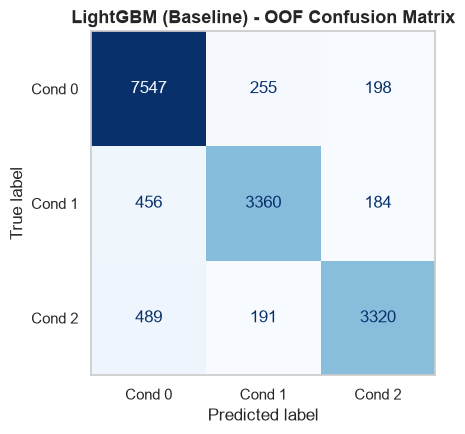

In [11]:
oof_lgb_base = np.zeros((len(train), 3))
test_lgb_base = np.zeros((len(test), 3)) if X_test is not None else None

t0 = time.time()
for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_lgb = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42 + fold,
        n_jobs=4,
        verbose=-1
    )
    clf_lgb.fit(X_tr, y_tr)
    oof_lgb_base[val_idx] = clf_lgb.predict_proba(X_va)
    if X_test is not None:
        test_lgb_base += clf_lgb.predict_proba(X_test) / N_SPLITS

    fold_acc = accuracy_score(y_val, np.argmax(oof_lgb_base[val_idx], axis=1))
    print(f"Fold {fold+1}/{N_SPLITS} Accuracy: {fold_acc*100:.2f}%")

print(f"Completed in {time.time() - t0:.1f}s\n")
evaluate_model_oof(y, oof_lgb_base, model_name="LightGBM", stage="Baseline");

### Model 2: XGBoost (Baseline)

Fold 1/5 Accuracy: 88.75%
Fold 2/5 Accuracy: 88.97%
Fold 3/5 Accuracy: 89.16%
Fold 4/5 Accuracy: 89.19%
Fold 5/5 Accuracy: 88.78%
Completed in 16.4s

XGBOOST (BASELINE) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.969%
  OOF Log-Loss       : 0.3031
  Macro Precision    : 89.013%
  Macro Recall       : 87.150%
  Macro F1-Score     : 87.991%
  Weighted F1-Score  : 88.885%
  Macro ROC-AUC (OvR): 0.9674

Classification Report:
              precision    recall  f1-score   support

           0     0.8888    0.9443    0.9157      8000
           1     0.8834    0.8407    0.8615      4000
           2     0.8982    0.8295    0.8625      4000

    accuracy                         0.8897     16000
   macro avg     0.8901    0.8715    0.8799     16000
weighted avg     0.8898    0.8897    0.8889     16000



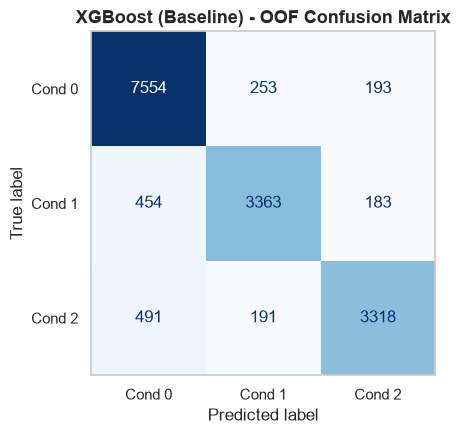

In [12]:
oof_xgb_base = np.zeros((len(train), 3))
test_xgb_base = np.zeros((len(test), 3)) if X_test is not None else None

t0 = time.time()
for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_xgb = xgb.XGBClassifier(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42 + fold,
        n_jobs=4,
        eval_metric="mlogloss"
    )
    clf_xgb.fit(X_tr, y_tr)
    oof_xgb_base[val_idx] = clf_xgb.predict_proba(X_va)
    if X_test is not None:
        test_xgb_base += clf_xgb.predict_proba(X_test) / N_SPLITS

    fold_acc = accuracy_score(y_val, np.argmax(oof_xgb_base[val_idx], axis=1))
    print(f"Fold {fold+1}/{N_SPLITS} Accuracy: {fold_acc*100:.2f}%")

print(f"Completed in {time.time() - t0:.1f}s\n")
evaluate_model_oof(y, oof_xgb_base, model_name="XGBoost", stage="Baseline");

### Model 3: CatBoost (Baseline)

Fold 1/5 Accuracy: 88.75%
Fold 2/5 Accuracy: 88.88%
Fold 3/5 Accuracy: 89.31%
Fold 4/5 Accuracy: 88.69%
Fold 5/5 Accuracy: 88.88%
Completed in 44.0s

CATBOOST (BASELINE) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.900%
  OOF Log-Loss       : 0.3082
  Macro Precision    : 88.863%
  Macro Recall       : 87.025%
  Macro F1-Score     : 87.856%
  Weighted F1-Score  : 88.811%
  Macro ROC-AUC (OvR): 0.9666

Classification Report:
              precision    recall  f1-score   support

           0     0.8900    0.9453    0.9168      8000
           1     0.8825    0.8355    0.8584      4000
           2     0.8934    0.8300    0.8605      4000

    accuracy                         0.8890     16000
   macro avg     0.8886    0.8702    0.8786     16000
weighted avg     0.8890    0.8890    0.8881     16000



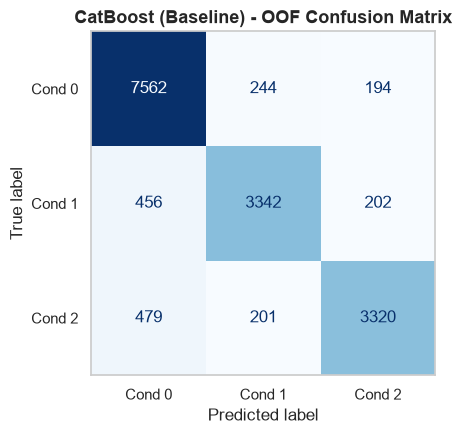

In [13]:
oof_cat_base = np.zeros((len(train), 3))
test_cat_base = np.zeros((len(test), 3)) if X_test is not None else None

t0 = time.time()
for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_cat = CatBoostClassifier(
        iterations=500,
        learning_rate=0.04,
        depth=6,
        l2_leaf_reg=3.0,
        random_seed=42 + fold,
        thread_count=4,
        verbose=0
    )
    clf_cat.fit(X_tr, y_tr)
    oof_cat_base[val_idx] = clf_cat.predict_proba(X_va)
    if X_test is not None:
        test_cat_base += clf_cat.predict_proba(X_test) / N_SPLITS

    fold_acc = accuracy_score(y_val, np.argmax(oof_cat_base[val_idx], axis=1))
    print(f"Fold {fold+1}/{N_SPLITS} Accuracy: {fold_acc*100:.2f}%")

print(f"Completed in {time.time() - t0:.1f}s\n")
evaluate_model_oof(y, oof_cat_base, model_name="CatBoost", stage="Baseline");

### Model 4: HistGradientBoosting (Baseline)

Fold 1/5 Accuracy: 88.78%
Fold 2/5 Accuracy: 88.59%
Fold 3/5 Accuracy: 88.78%
Fold 4/5 Accuracy: 89.00%
Fold 5/5 Accuracy: 88.75%
Completed in 5.2s

HISTGRADIENTBOOSTING (BASELINE) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.781%
  OOF Log-Loss       : 0.3062
  Macro Precision    : 88.803%
  Macro Recall       : 86.904%
  Macro F1-Score     : 87.761%
  Weighted F1-Score  : 88.692%
  Macro ROC-AUC (OvR): 0.9670

Classification Report:
              precision    recall  f1-score   support

           0     0.8873    0.9441    0.9148      8000
           1     0.8839    0.8320    0.8572      4000
           2     0.8928    0.8310    0.8608      4000

    accuracy                         0.8878     16000
   macro avg     0.8880    0.8690    0.8776     16000
weighted avg     0.8879    0.8878    0.8869     16000



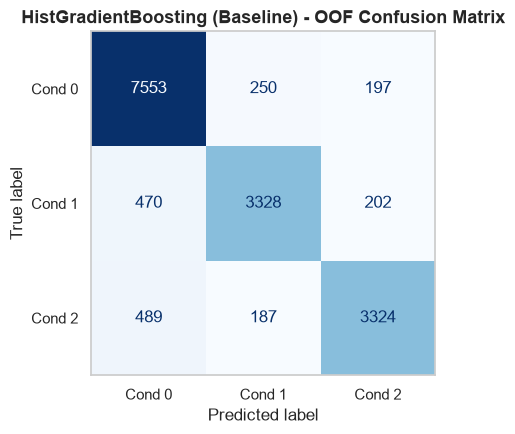

In [14]:
oof_hgb_base = np.zeros((len(train), 3))
test_hgb_base = np.zeros((len(test), 3)) if X_test is not None else None

t0 = time.time()
for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_hgb = HistGradientBoostingClassifier(
        max_iter=400,
        learning_rate=0.03,
        max_depth=6,
        l2_regularization=1.0,
        random_state=42 + fold
    )
    clf_hgb.fit(X_tr, y_tr)
    oof_hgb_base[val_idx] = clf_hgb.predict_proba(X_va)
    if X_test is not None:
        test_hgb_base += clf_hgb.predict_proba(X_test) / N_SPLITS

    fold_acc = accuracy_score(y_val, np.argmax(oof_hgb_base[val_idx], axis=1))
    print(f"Fold {fold+1}/{N_SPLITS} Accuracy: {fold_acc*100:.2f}%")

print(f"Completed in {time.time() - t0:.1f}s\n")
evaluate_model_oof(y, oof_hgb_base, model_name="HistGradientBoosting", stage="Baseline");

### Model 5: ExtraTrees (Baseline)
`ExtraTreesClassifier` uses the median-imputed matrices (`X_imp`, `X_test_imp`).

Fold 1/5 Accuracy: 88.00%
Fold 2/5 Accuracy: 88.06%
Fold 3/5 Accuracy: 87.72%
Fold 4/5 Accuracy: 87.94%
Fold 5/5 Accuracy: 87.41%
Completed in 5.1s

EXTRATREES (BASELINE) - 5-FOLD OOF METRICS
  OOF Accuracy       : 87.825%
  OOF Log-Loss       : 0.3508
  Macro Precision    : 88.049%
  Macro Recall       : 85.371%
  Macro F1-Score     : 86.528%
  Weighted F1-Score  : 87.671%
  Macro ROC-AUC (OvR): 0.9623

Classification Report:
              precision    recall  f1-score   support

           0     0.8735    0.9519    0.9110      8000
           1     0.8870    0.7987    0.8406      4000
           2     0.8810    0.8105    0.8443      4000

    accuracy                         0.8782     16000
   macro avg     0.8805    0.8537    0.8653     16000
weighted avg     0.8787    0.8782    0.8767     16000



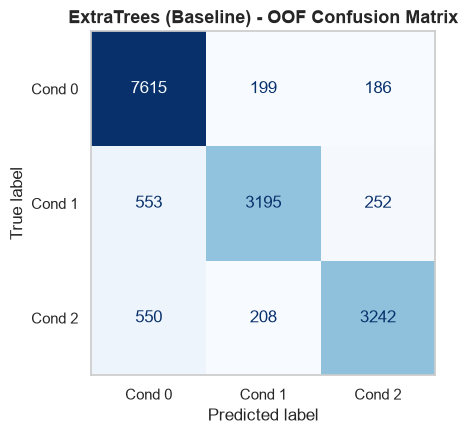

In [15]:
oof_et_base = np.zeros((len(train), 3))
test_et_base = np.zeros((len(test), 3)) if X_test_imp is not None else None

t0 = time.time()
for fold, (trn_idx, val_idx) in enumerate(skf.split(X_imp, y)):
    X_tr_imp, y_tr = X_imp.iloc[trn_idx], y[trn_idx]
    X_va_imp, y_val = X_imp.iloc[val_idx], y[val_idx]

    clf_et = ExtraTreesClassifier(
        n_estimators=250,
        max_depth=18,
        min_samples_split=4,
        random_state=42 + fold,
        n_jobs=4
    )
    clf_et.fit(X_tr_imp, y_tr)
    oof_et_base[val_idx] = clf_et.predict_proba(X_va_imp)
    if X_test_imp is not None:
        test_et_base += clf_et.predict_proba(X_test_imp) / N_SPLITS

    fold_acc = accuracy_score(y_val, np.argmax(oof_et_base[val_idx], axis=1))
    print(f"Fold {fold+1}/{N_SPLITS} Accuracy: {fold_acc*100:.2f}%")

print(f"Completed in {time.time() - t0:.1f}s\n")
evaluate_model_oof(y, oof_et_base, model_name="ExtraTrees", stage="Baseline");

### Baseline Models Summary Comparison

In [16]:
baseline_df = pd.DataFrame([m for m in metrics_registry if m["Stage"] == "Baseline"]).sort_values("Accuracy (%)", ascending=False)
display(baseline_df)

,Model,Stage,Accuracy (%),Log-Loss,Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%),ROC-AUC (OvR)
1,XGBoost,Baseline,88.969,0.3031,89.013,87.150,87.991,88.885,0.9674
0,LightGBM,Baseline,88.919,0.3071,88.945,87.112,87.941,88.836,0.9669
2,CatBoost,Baseline,88.900,0.3082,88.863,87.025,87.856,88.811,0.9666
3,HistGradientBoosting,Baseline,88.781,0.3062,88.803,86.904,87.761,88.692,0.9670
4,ExtraTrees,Baseline,87.825,0.3508,88.049,85.371,86.528,87.671,0.9623


## Phase 2: Hyperparameter Fine-Tuning & Re-Evaluation of Each Model
For each of the 5 models, we run a stratified hyperparameter search (`RandomizedSearchCV` optimizing `neg_log_loss`) to find the best hyperparameters, and then run full **5-Fold Stratified Cross-Validation** with those tuned parameters to compute the post-tuning OOF Accuracy, Log-Loss, Precision, Recall, F1, ROC-AUC, Classification Report, and Confusion Matrix.

### 7.1 Fine-Tuning & Evaluating Model 1: LightGBM


Searching optimal hyperparameters for LightGBM...
Best LightGBM Params: {'subsample': 0.9, 'reg_lambda': 2.0, 'reg_alpha': 1.0, 'num_leaves': 31, 'n_estimators': 700, 'min_child_samples': 20, 'max_depth': 5, 'learning_rate': 0.02, 'colsample_bytree': 0.7}
LIGHTGBM (FINE-TUNED) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.975%
  OOF Log-Loss       : 0.3029
  Macro Precision    : 88.966%
  Macro Recall       : 87.200%
  Macro F1-Score     : 88.000%
  Weighted F1-Score  : 88.895%
  Macro ROC-AUC (OvR): 0.9674

Classification Report:
              precision    recall  f1-score   support

           0     0.8901    0.9430    0.9158      8000
           1     0.8819    0.8423    0.8616      4000
           2     0.8969    0.8307    0.8626      4000

    accuracy                         0.8898     16000
   macro avg     0.8897    0.8720    0.8800     16000
weighted avg     0.8898    0.8898    0.8890     16000



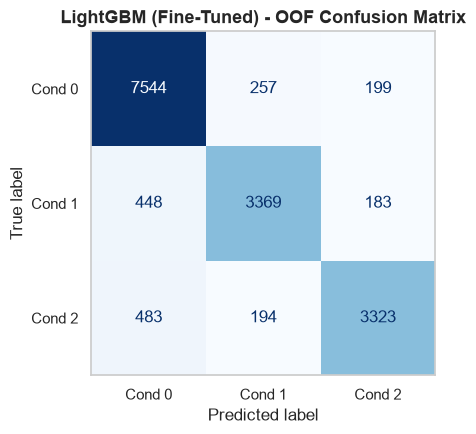

In [17]:
print("Searching optimal hyperparameters for LightGBM...")
lgb_param_grid = {
    "n_estimators": [500, 700, 900],
    "learning_rate": [0.02, 0.03, 0.04],
    "num_leaves": [23, 31, 45, 63],
    "max_depth": [5, 6, 7, 8],
    "min_child_samples": [15, 20, 30, 50],
    "subsample": [0.75, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "reg_alpha": [0.05, 0.1, 0.5, 1.0],
    "reg_lambda": [0.5, 1.0, 2.0, 5.0]
}

lgb_search = RandomizedSearchCV(
    estimator=lgb.LGBMClassifier(random_state=42, n_jobs=4, verbose=-1),
    param_distributions=lgb_param_grid,
    n_iter=12,
    scoring="neg_log_loss",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1
)
lgb_search.fit(X, y)
best_lgb_params = lgb_search.best_params_
print("Best LightGBM Params:", best_lgb_params)

# 5-Fold Stratified CV Evaluation with Fine-Tuned LightGBM
oof_lgb_tuned = np.zeros((len(train), 3))
test_lgb_tuned = np.zeros((len(test), 3)) if X_test is not None else None

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_lgb_tuned = lgb.LGBMClassifier(**best_lgb_params, random_state=42 + fold, n_jobs=4, verbose=-1)
    clf_lgb_tuned.fit(X_tr, y_tr)
    oof_lgb_tuned[val_idx] = clf_lgb_tuned.predict_proba(X_va)
    if X_test is not None:
        test_lgb_tuned += clf_lgb_tuned.predict_proba(X_test) / N_SPLITS

evaluate_model_oof(y, oof_lgb_tuned, model_name="LightGBM", stage="Fine-Tuned");

### Fine-Tuning & Evaluating Model 2: XGBoost

Searching optimal hyperparameters for XGBoost...
Best XGBoost Params: {'subsample': 0.9, 'reg_lambda': 0.5, 'reg_alpha': 0.05, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.05, 'colsample_bytree': 0.8}
XGBOOST (FINE-TUNED) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.931%
  OOF Log-Loss       : 0.3019
  Macro Precision    : 88.980%
  Macro Recall       : 87.087%
  Macro F1-Score     : 87.942%
  Weighted F1-Score  : 88.845%
  Macro ROC-AUC (OvR): 0.9676

Classification Report:
              precision    recall  f1-score   support

           0     0.8882    0.9446    0.9156      8000
           1     0.8861    0.8363    0.8605      4000
           2     0.8951    0.8317    0.8623      4000

    accuracy                         0.8893     16000
   macro avg     0.8898    0.8709    0.8794     16000
weighted avg     0.8894    0.8893    0.8885     16000



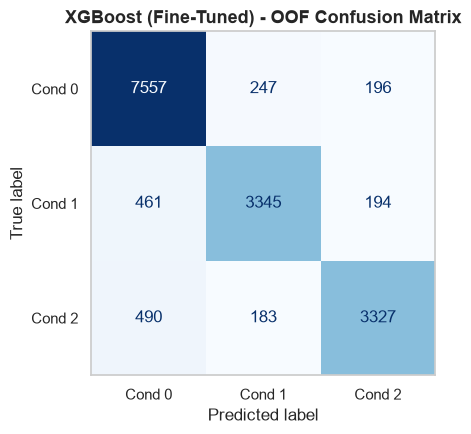

In [18]:
print("Searching optimal hyperparameters for XGBoost...")
xgb_param_grid = {
    "n_estimators": [500, 650, 800],
    "learning_rate": [0.02, 0.03, 0.04],
    "max_depth": [4, 5, 6, 7],
    "min_child_weight": [1, 3, 5],
    "gamma": [0.0, 0.05, 0.1],
    "subsample": [0.75, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "reg_alpha": [0.05, 0.1, 0.5],
    "reg_lambda": [0.5, 1.0, 2.0, 5.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(random_state=42, n_jobs=4, eval_metric="mlogloss"),
    param_distributions=xgb_param_grid,
    n_iter=12,
    scoring="neg_log_loss",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1
)
xgb_search.fit(X, y)
best_xgb_params = xgb_search.best_params_
print("Best XGBoost Params:", best_xgb_params)

# 5-Fold Stratified CV Evaluation with Fine-Tuned XGBoost
oof_xgb_tuned = np.zeros((len(train), 3))
test_xgb_tuned = np.zeros((len(test), 3)) if X_test is not None else None

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_xgb_tuned = xgb.XGBClassifier(**best_xgb_params, random_state=42 + fold, n_jobs=4, eval_metric="mlogloss")
    clf_xgb_tuned.fit(X_tr, y_tr)
    oof_xgb_tuned[val_idx] = clf_xgb_tuned.predict_proba(X_va)
    if X_test is not None:
        test_xgb_tuned += clf_xgb_tuned.predict_proba(X_test) / N_SPLITS

evaluate_model_oof(y, oof_xgb_tuned, model_name="XGBoost", stage="Fine-Tuned");

### Fine-Tuning & Evaluating Model 3: CatBoost

Searching optimal hyperparameters for CatBoost...
Best CatBoost Params: {'random_strength': 1.0, 'learning_rate': 0.05, 'l2_leaf_reg': 3.0, 'iterations': 900, 'depth': 6}
CATBOOST (FINE-TUNED) - 5-FOLD OOF METRICS
  OOF Accuracy       : 89.006%
  OOF Log-Loss       : 0.3032
  Macro Precision    : 89.032%
  Macro Recall       : 87.179%
  Macro F1-Score     : 88.015%
  Weighted F1-Score  : 88.922%
  Macro ROC-AUC (OvR): 0.9675

Classification Report:
              precision    recall  f1-score   support

           0     0.8896    0.9449    0.9164      8000
           1     0.8839    0.8410    0.8619      4000
           2     0.8975    0.8295    0.8622      4000

    accuracy                         0.8901     16000
   macro avg     0.8903    0.8718    0.8802     16000
weighted avg     0.8901    0.8901    0.8892     16000



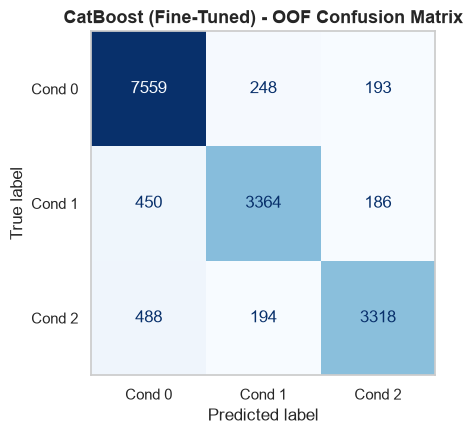

In [19]:
print("Searching optimal hyperparameters for CatBoost...")
cat_param_grid = {
    "iterations": [500, 700, 900],
    "learning_rate": [0.03, 0.04, 0.05],
    "depth": [5, 6, 7],
    "l2_leaf_reg": [1.5, 3.0, 5.0, 7.0],
    "random_strength": [0.5, 1.0, 2.0]
}

cat_search = RandomizedSearchCV(
    estimator=CatBoostClassifier(random_seed=42, thread_count=4, verbose=0),
    param_distributions=cat_param_grid,
    n_iter=8,
    scoring="neg_log_loss",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1
)
cat_search.fit(X, y)
best_cat_params = cat_search.best_params_
print("Best CatBoost Params:", best_cat_params)

# 5-Fold Stratified CV Evaluation with Fine-Tuned CatBoost
oof_cat_tuned = np.zeros((len(train), 3))
test_cat_tuned = np.zeros((len(test), 3)) if X_test is not None else None

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_cat_tuned = CatBoostClassifier(**best_cat_params, random_seed=42 + fold, thread_count=4, verbose=0)
    clf_cat_tuned.fit(X_tr, y_tr)
    oof_cat_tuned[val_idx] = clf_cat_tuned.predict_proba(X_va)
    if X_test is not None:
        test_cat_tuned += clf_cat_tuned.predict_proba(X_test) / N_SPLITS

evaluate_model_oof(y, oof_cat_tuned, model_name="CatBoost", stage="Fine-Tuned");

### Fine-Tuning & Evaluating Model 4: HistGradientBoosting

Searching optimal hyperparameters for HistGradientBoosting...
Best HistGradientBoosting Params: {'min_samples_leaf': 50, 'max_leaf_nodes': 31, 'max_iter': 550, 'max_depth': 5, 'learning_rate': 0.04, 'l2_regularization': 5.0}
HISTGRADIENTBOOSTING (FINE-TUNED) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.825%
  OOF Log-Loss       : 0.3057
  Macro Precision    : 88.792%
  Macro Recall       : 86.975%
  Macro F1-Score     : 87.798%
  Weighted F1-Score  : 88.738%
  Macro ROC-AUC (OvR): 0.9671

Classification Report:
              precision    recall  f1-score   support

           0     0.8891    0.9437    0.9156      8000
           1     0.8837    0.8343    0.8583      4000
           2     0.8909    0.8313    0.8601      4000

    accuracy                         0.8882     16000
   macro avg     0.8879    0.8698    0.8780     16000
weighted avg     0.8882    0.8882    0.8874     16000



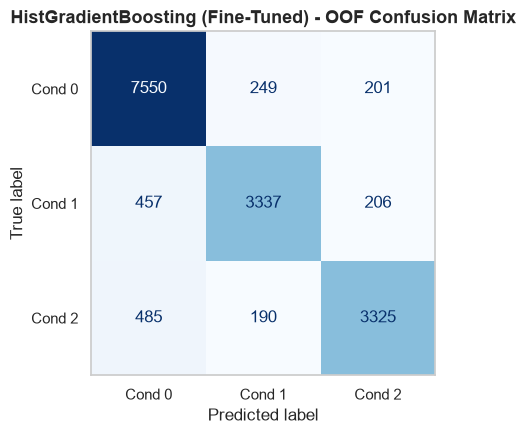

In [20]:
print("Searching optimal hyperparameters for HistGradientBoosting...")
hgb_param_grid = {
    "max_iter": [400, 550, 700],
    "learning_rate": [0.02, 0.03, 0.04],
    "max_leaf_nodes": [23, 31, 45, 63],
    "max_depth": [5, 6, 7, 8],
    "min_samples_leaf": [15, 20, 30, 50],
    "l2_regularization": [0.5, 1.0, 2.5, 5.0]
}

hgb_search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(random_state=42),
    param_distributions=hgb_param_grid,
    n_iter=12,
    scoring="neg_log_loss",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=4
)
hgb_search.fit(X, y)
best_hgb_params = hgb_search.best_params_
print("Best HistGradientBoosting Params:", best_hgb_params)

# 5-Fold Stratified CV Evaluation with Fine-Tuned HistGradientBoosting
oof_hgb_tuned = np.zeros((len(train), 3))
test_hgb_tuned = np.zeros((len(test), 3)) if X_test is not None else None

for fold, (trn_idx, val_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X.iloc[trn_idx], y[trn_idx]
    X_va, y_val = X.iloc[val_idx], y[val_idx]

    clf_hgb_tuned = HistGradientBoostingClassifier(**best_hgb_params, random_state=42 + fold)
    clf_hgb_tuned.fit(X_tr, y_tr)
    oof_hgb_tuned[val_idx] = clf_hgb_tuned.predict_proba(X_va)
    if X_test is not None:
        test_hgb_tuned += clf_hgb_tuned.predict_proba(X_test) / N_SPLITS

evaluate_model_oof(y, oof_hgb_tuned, model_name="HistGradientBoosting", stage="Fine-Tuned");

### Fine-Tuning & Evaluating Model 5: ExtraTrees

Searching optimal hyperparameters for ExtraTrees...
Best ExtraTrees Params: {'n_estimators': 400, 'min_samples_split': 6, 'min_samples_leaf': 2, 'max_features': 0.6, 'max_depth': 16, 'criterion': 'gini'}
EXTRATREES (FINE-TUNED) - 5-FOLD OOF METRICS
  OOF Accuracy       : 88.344%
  OOF Log-Loss       : 0.3260
  Macro Precision    : 88.405%
  Macro Recall       : 86.163%
  Macro F1-Score     : 87.155%
  Weighted F1-Score  : 88.222%
  Macro ROC-AUC (OvR): 0.9645

Classification Report:
              precision    recall  f1-score   support

           0     0.8821    0.9489    0.9142      8000
           1     0.8839    0.8165    0.8489      4000
           2     0.8862    0.8195    0.8515      4000

    accuracy                         0.8834     16000
   macro avg     0.8840    0.8616    0.8715     16000
weighted avg     0.8836    0.8834    0.8822     16000



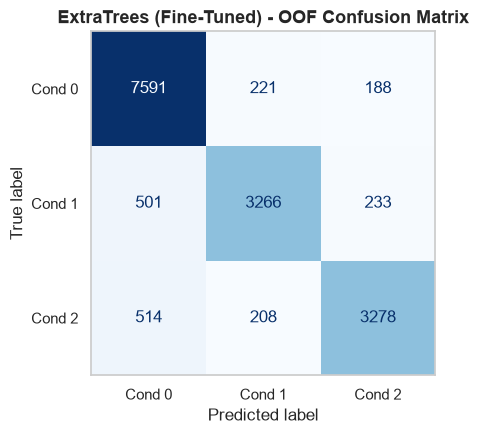

In [21]:
print("Searching optimal hyperparameters for ExtraTrees...")
et_param_grid = {
    "n_estimators": [300, 400, 500],
    "max_depth": [16, 18, 22, None],
    "min_samples_split": [2, 4, 6],
    "min_samples_leaf": [1, 2, 3],
    "max_features": ["sqrt", 0.4, 0.6],
    "criterion": ["gini", "entropy", "log_loss"]
}

et_search = RandomizedSearchCV(
    estimator=ExtraTreesClassifier(random_state=42, n_jobs=4),
    param_distributions=et_param_grid,
    n_iter=12,
    scoring="neg_log_loss",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=1
)
et_search.fit(X_imp, y)
best_et_params = et_search.best_params_
print("Best ExtraTrees Params:", best_et_params)

# 5-Fold Stratified CV Evaluation with Fine-Tuned ExtraTrees
oof_et_tuned = np.zeros((len(train), 3))
test_et_tuned = np.zeros((len(test), 3)) if X_test_imp is not None else None

for fold, (trn_idx, val_idx) in enumerate(skf.split(X_imp, y)):
    X_tr_imp, y_tr = X_imp.iloc[trn_idx], y[trn_idx]
    X_va_imp, y_val = X_imp.iloc[val_idx], y[val_idx]

    clf_et_tuned = ExtraTreesClassifier(**best_et_params, random_state=42 + fold, n_jobs=4)
    clf_et_tuned.fit(X_tr_imp, y_tr)
    oof_et_tuned[val_idx] = clf_et_tuned.predict_proba(X_va_imp)
    if X_test_imp is not None:
        test_et_tuned += clf_et_tuned.predict_proba(X_test_imp) / N_SPLITS

evaluate_model_oof(y, oof_et_tuned, model_name="ExtraTrees", stage="Fine-Tuned");

### Baseline vs. Fine-Tuned Performance Comparison
Compare all 5 models before and after hyperparameter tuning across Accuracy, Log-Loss, Macro F1, and ROC-AUC, and select the best OOF probability matrix per model family for the final ensemble.


,Model,Stage,Accuracy (%),Log-Loss,Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%),ROC-AUC (OvR)
2,CatBoost,Baseline,88.900,0.3082,88.863,87.025,87.856,88.811,0.9666
7,CatBoost,Fine-Tuned,89.006,0.3032,89.032,87.179,88.015,88.922,0.9675
4,ExtraTrees,Baseline,87.825,0.3508,88.049,85.371,86.528,87.671,0.9623
9,ExtraTrees,Fine-Tuned,88.344,0.3260,88.405,86.163,87.155,88.222,0.9645
3,HistGradientBoosting,Baseline,88.781,0.3062,88.803,86.904,87.761,88.692,0.9670
8,HistGradientBoosting,Fine-Tuned,88.825,0.3057,88.792,86.975,87.798,88.738,0.9671
0,LightGBM,Baseline,88.919,0.3071,88.945,87.112,87.941,88.836,0.9669
5,LightGBM,Fine-Tuned,88.975,0.3029,88.966,87.200,88.000,88.895,0.9674
1,XGBoost,Baseline,88.969,0.3031,89.013,87.150,87.991,88.885,0.9674
6,XGBoost,Fine-Tuned,88.931,0.3019,88.980,87.087,87.942,88.845,0.9676


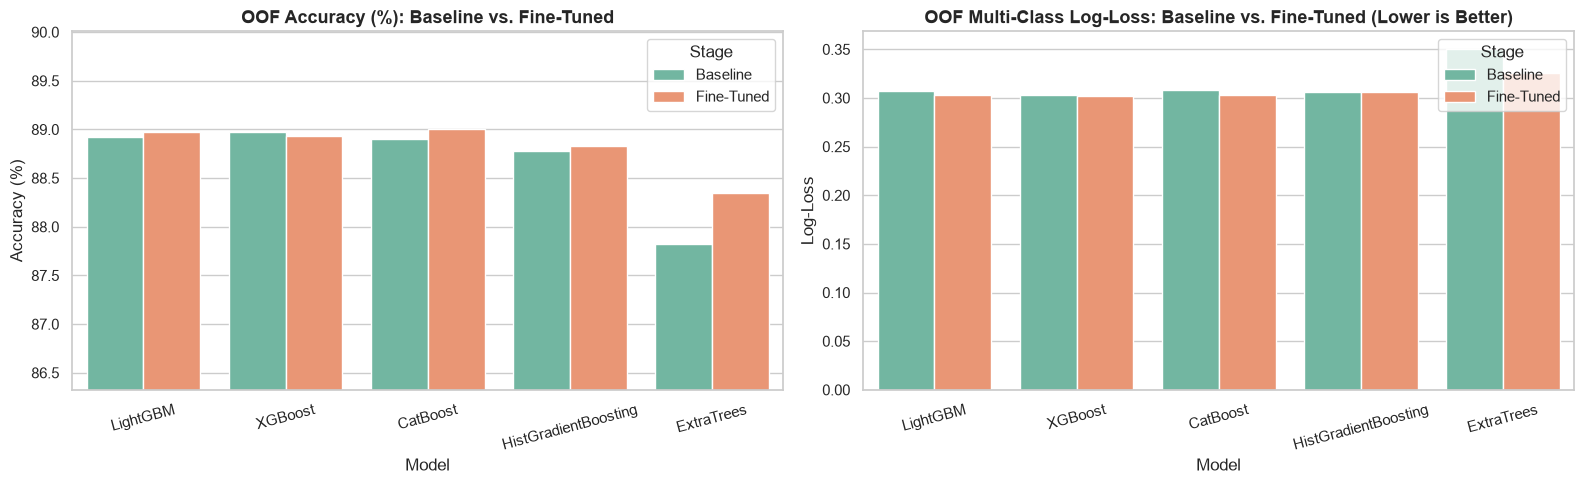

Selected Fine-Tuned LightGBM             (Log-Loss: 0.3029 vs Baseline 0.3071)
Selected Fine-Tuned XGBoost              (Log-Loss: 0.3019 vs Baseline 0.3031)
Selected Fine-Tuned CatBoost             (Log-Loss: 0.3032 vs Baseline 0.3082)
Selected Fine-Tuned HistGradientBoosting (Log-Loss: 0.3057 vs Baseline 0.3062)
Selected Fine-Tuned ExtraTrees           (Log-Loss: 0.3260 vs Baseline 0.3508)


In [22]:
comparison_df = pd.DataFrame(metrics_registry)
display(comparison_df.sort_values(["Model", "Stage"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=comparison_df, x="Model", y="Accuracy (%)", hue="Stage", palette="Set2", ax=axes[0])
axes[0].set_title("OOF Accuracy (%): Baseline vs. Fine-Tuned")
axes[0].set_ylim(comparison_df["Accuracy (%)"].min() - 1.5, comparison_df["Accuracy (%)"].max() + 1.0)
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(data=comparison_df, x="Model", y="Log-Loss", hue="Stage", palette="Set2", ax=axes[1])
axes[1].set_title("OOF Multi-Class Log-Loss: Baseline vs. Fine-Tuned (Lower is Better)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

# Automatically select the better version (Baseline vs Fine-Tuned by Log-Loss) for each model family
def select_best(base_oof, tuned_oof, base_test, tuned_test, name):
    ll_base = log_loss(y, base_oof)
    ll_tuned = log_loss(y, tuned_oof)
    if ll_tuned <= ll_base:
        print(f"Selected Fine-Tuned {name:20s} (Log-Loss: {ll_tuned:.4f} vs Baseline {ll_base:.4f})")
        return tuned_oof, tuned_test
    else:
        print(f"Selected Baseline   {name:20s} (Log-Loss: {ll_base:.4f} vs Fine-Tuned {ll_tuned:.4f})")
        return base_oof, base_test

oof_lgb, test_lgb = select_best(oof_lgb_base, oof_lgb_tuned, test_lgb_base, test_lgb_tuned, "LightGBM")
oof_xgb, test_xgb = select_best(oof_xgb_base, oof_xgb_tuned, test_xgb_base, test_xgb_tuned, "XGBoost")
oof_cat, test_cat = select_best(oof_cat_base, oof_cat_tuned, test_cat_base, test_cat_tuned, "CatBoost")
oof_hgb, test_hgb = select_best(oof_hgb_base, oof_hgb_tuned, test_hgb_base, test_hgb_tuned, "HistGradientBoosting")
oof_et,  test_et  = select_best(oof_et_base,  oof_et_tuned,  test_et_base,  test_et_tuned,  "ExtraTrees")

## Phase 3: Optimal Ensemble Blending (SciPy SLSQP) & Final Metrics
Using `scipy.optimize.minimize` (`method='SLSQP'`), we find the convex combination of model weights ($w_i \in [0, 1], \sum w_i = 1$) that minimizes out-of-fold multi-class `log_loss`, then evaluate the final ensemble across all classification metrics.

FINDING OPTIMAL BLEND WEIGHTS
Optimized Model Weights:
  LightGBM              : 28.73%
  XGBoost               : 25.33%
  CatBoost              : 39.46%
  HistGradientBoosting  : 6.48%
  ExtraTrees            : 0.00%
ENSEMBLE  (ENSEMBLE) - 5-FOLD OOF METRICS
  OOF Accuracy       : 89.094%
  OOF Log-Loss       : 0.2994
  Macro Precision    : 89.141%
  Macro Recall       : 87.288%
  Macro F1-Score     : 88.125%
  Weighted F1-Score  : 89.012%
  Macro ROC-AUC (OvR): 0.9682

Classification Report:
              precision    recall  f1-score   support

           0     0.8899    0.9451    0.9167      8000
           1     0.8855    0.8413    0.8628      4000
           2     0.8988    0.8323    0.8642      4000

    accuracy                         0.8909     16000
   macro avg     0.8914    0.8729    0.8813     16000
weighted avg     0.8910    0.8909    0.8901     16000



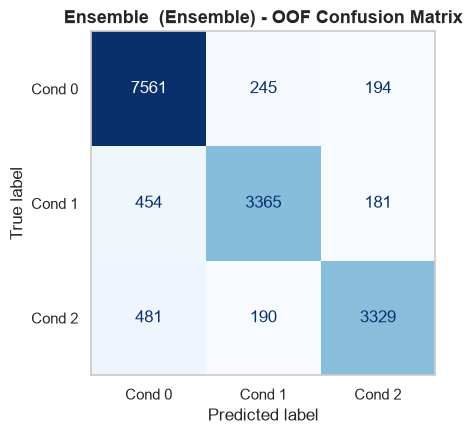


COMPLETE LEADERBOARD: BASELINE vs. FINE-TUNED vs. ENSEMBLE


,Model,Stage,Accuracy (%),Log-Loss,Macro Precision (%),Macro Recall (%),Macro F1 (%),Weighted F1 (%),ROC-AUC (OvR)
0,Ensemble,Ensemble,89.094,0.2994,89.141,87.288,88.125,89.012,0.9682
1,CatBoost,Fine-Tuned,89.006,0.3032,89.032,87.179,88.015,88.922,0.9675
2,LightGBM,Fine-Tuned,88.975,0.3029,88.966,87.200,88.000,88.895,0.9674
3,XGBoost,Baseline,88.969,0.3031,89.013,87.150,87.991,88.885,0.9674
4,XGBoost,Fine-Tuned,88.931,0.3019,88.980,87.087,87.942,88.845,0.9676
5,LightGBM,Baseline,88.919,0.3071,88.945,87.112,87.941,88.836,0.9669
6,CatBoost,Baseline,88.900,0.3082,88.863,87.025,87.856,88.811,0.9666
7,HistGradientBoosting,Fine-Tuned,88.825,0.3057,88.792,86.975,87.798,88.738,0.9671
8,HistGradientBoosting,Baseline,88.781,0.3062,88.803,86.904,87.761,88.692,0.9670
9,ExtraTrees,Fine-Tuned,88.344,0.3260,88.405,86.163,87.155,88.222,0.9645


In [23]:
print("=" * 60)
print("FINDING OPTIMAL BLEND WEIGHTS")
print("=" * 60)

models_oof = {
    "LightGBM": oof_lgb,
    "XGBoost": oof_xgb,
    "CatBoost": oof_cat,
    "HistGradientBoosting": oof_hgb,
    "ExtraTrees": oof_et
}

model_names = list(models_oof.keys())
oof_list = [models_oof[name] for name in model_names]

def loss_func(weights):
    weights = np.array(weights)
    weights = weights / np.sum(weights)
    blend_probs = sum(w * p for w, p in zip(weights, oof_list))
    return log_loss(y, blend_probs)

init_weights = [1.0 / len(model_names)] * len(model_names)
bounds = [(0, 1) for _ in range(len(model_names))]
constraints = ({"type": "eq", "fun": lambda w: 1.0 - sum(w)})

res = minimize(loss_func, init_weights, bounds=bounds, constraints=constraints, method="SLSQP")
opt_weights = res.x / np.sum(res.x)

print("Optimized Model Weights:")
for name, w in zip(model_names, opt_weights):
    print(f"  {name:22s}: {w*100:.2f}%")

# Compute Equal-Weight Blend and Optimal Weighted Ensemble OOF Probabilities
equal_oof_probs = sum(oof_list) / len(oof_list)
final_oof_probs = sum(w * p for w, p in zip(opt_weights, oof_list))
final_oof_preds = np.argmax(final_oof_probs, axis=1)

# Evaluate Equal-Weight Blend (without plotting CM) and Optimal Ensemble (with CM)
evaluate_model_oof(y, final_oof_probs, model_name="Ensemble ", stage="Ensemble", plot_cm=True)

# Final Leaderboard across all Baseline, Fine-Tuned, and Ensemble models
print("\n" + "=" * 65)
print("COMPLETE LEADERBOARD: BASELINE vs. FINE-TUNED vs. ENSEMBLE")
print("=" * 65)
leaderboard_df = pd.DataFrame(metrics_registry).sort_values(["Accuracy (%)", "ROC-AUC (OvR)"], ascending=[False, False]).reset_index(drop=True)
display(leaderboard_df)

In [24]:
# Generate Test Predictions if test set is available
if X_test is not None:
    test_list = [test_lgb, test_xgb, test_cat, test_hgb, test_et]
    final_test_probs = sum(w * p for w, p in zip(opt_weights, test_list))
    final_test_preds = np.argmax(final_test_probs, axis=1)

    sub = pd.DataFrame({
        "unit_id": test["unit_id"],
        "condition": final_test_preds
    })
    sub.to_csv(r"D:\IIIT Bangalore\Sem-1\Machine Learning\Machine Learning Projects\Industrial Machine Fault Prediction\submission.csv", index=False)
    print("\n" + "=" * 60)
    print(f"Submission saved to 'submission.csv'! Total rows: {len(sub)}")
    print("=" * 60)


Submission saved to 'submission.csv'! Total rows: 4000
